In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = sns.load_dataset('titanic')

# Statistik deskriptif variabel numerik
print(df.describe())

# Statistik deskriptif variabel kategorikal
print(df.describe(include='object'))

         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200
         sex embarked  who  embark_town alive
count    891      889  891          889   891
unique     2        3    3            3     2
top     male        S  man  Southampton    no
freq     577      644  537          644   549


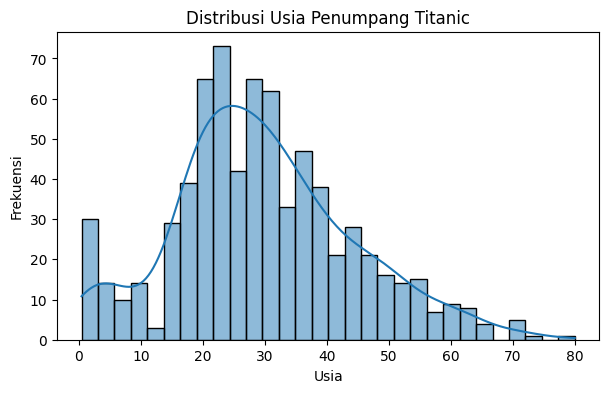

In [4]:
plt.figure(figsize=(7,4))
sns.histplot(df['age'].dropna(), bins=30, kde=True)
plt.title('Distribusi Usia Penumpang Titanic')
plt.xlabel('Usia')
plt.ylabel('Frekuensi')
plt.show()

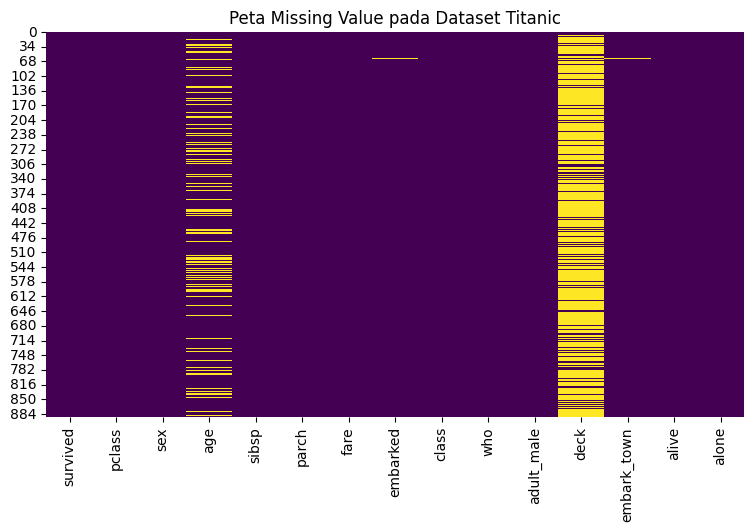

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [5]:
plt.figure(figsize=(9,5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Peta Missing Value pada Dataset Titanic')
plt.show()

print(df.isnull().sum())

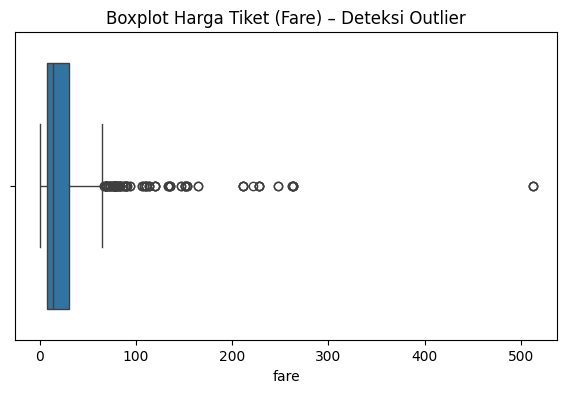

Jumlah outlier pada kolom fare: 116
Q1 = 7.9104, Q3 = 31.0, IQR = 23.0896, batas_bawah = -26.724, batas_atas = 65.6344


In [6]:
plt.figure(figsize=(7,4))
sns.boxplot(x=df['fare'])
plt.title('Boxplot Harga Tiket (Fare) – Deteksi Outlier')
plt.show()

# Deteksi outlier menggunakan metode IQR
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
outliers = df[(df['fare'] < batas_bawah) | (df['fare'] > batas_atas)]

print('Jumlah outlier pada kolom fare:', len(outliers))

# Untuk tambahan analisis
print(f"Q1 = {Q1}, "
    f"Q3 = {Q3}, "
    f"IQR = {IQR}, "
    f"batas_bawah = {batas_bawah}, "
    f"batas_atas = {batas_atas}"
)

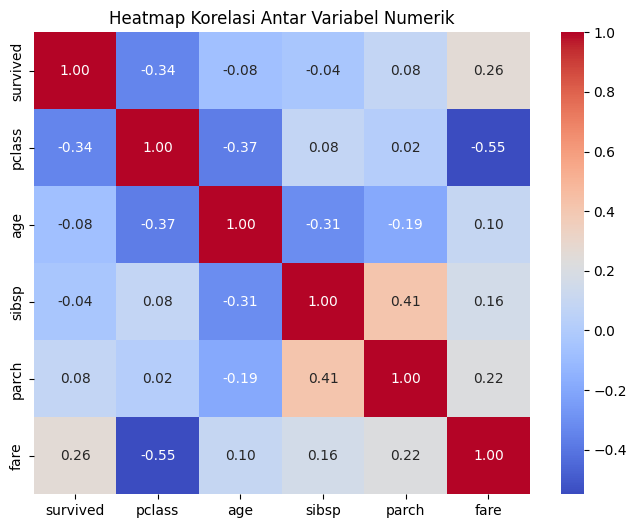

In [7]:
plt.figure(figsize=(8,6))
kolom_numerik = df.select_dtypes(include=['int64','float64'])
sns.heatmap(kolom_numerik.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap Korelasi Antar Variabel Numerik')
plt.show()

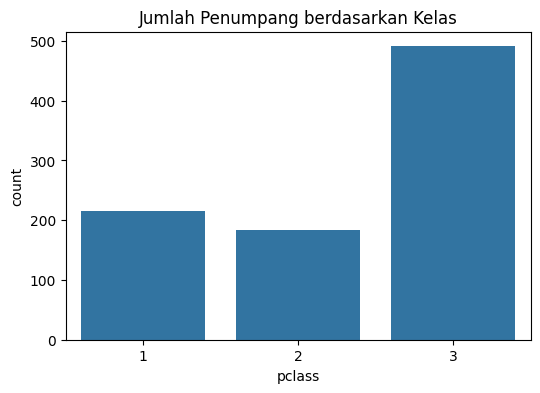

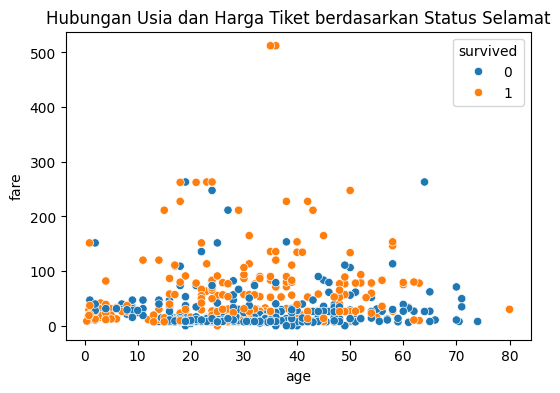

In [8]:
# Bar chart: jumlah penumpang per kelas
plt.figure(figsize=(6,4))
sns.countplot(x='pclass', data=df)
plt.title('Jumlah Penumpang berdasarkan Kelas')
plt.show()

# Scatter plot: hubungan usia dan harga tiket
plt.figure(figsize=(6,4))
sns.scatterplot(x='age', y='fare', hue='survived', data=df)
plt.title('Hubungan Usia dan Harga Tiket berdasarkan Status Selamat')
plt.show()

In [9]:
df_clean = df.copy()
df_clean['age'] = df_clean['age'].fillna(df_clean['age'].median())
df_clean['embarked'] = df_clean['embarked'].fillna(df_clean['embarked'].mode()[0])
df_clean = df_clean.drop(columns=['deck'], errors='ignore')
df_clean = df_clean.dropna(subset=['embarked'])

print('Missing value setelah cleaning:', df_clean.isnull().sum().sum())

Missing value setelah cleaning: 2


In [10]:
from sklearn.preprocessing import LabelEncoder

# Label Encoding untuk kolom biner (sex)
le = LabelEncoder()
df_clean['sex_encoded'] = le.fit_transform(df_clean['sex'])

# One-Hot Encoding untuk kolom dengan >2 kategori (embarked)
df_clean = pd.get_dummies(df_clean, columns=['embarked'], prefix='embarked')
df_clean.head()

,survived,pclass,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,sex_encoded,embarked_C,embarked_Q,embarked_S
0,0,3,male,22.0,1,0,7.2500,Third,man,True,Southampton,no,False,1,False,False,True
1,1,1,female,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False,0,True,False,False
2,1,3,female,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True,0,False,False,True
3,1,1,female,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False,0,False,False,True
4,0,3,male,35.0,0,0,8.0500,Third,man,True,Southampton,no,True,1,False,False,True


In [11]:
# Feature engineering: membuat kolom family_size dari sibsp + parch
df_clean['family_size'] = df_clean['sibsp'] + df_clean['parch'] + 1

# Feature engineering: kategori usia
def kategori_usia(usia):
 if usia < 18: return 'Anak'
 elif usia < 60: return 'Dewasa'
 else: return 'Lansia'
df_clean['kategori_usia'] = df_clean['age'].apply(kategori_usia)
print(df_clean[['family_size','kategori_usia']].head())

   family_size kategori_usia
0            2        Dewasa
1            2        Dewasa
2            1        Dewasa
3            2        Dewasa
4            1        Dewasa


In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
kolom_scaling = ['age', 'fare', 'family_size']
df_clean[kolom_scaling] = scaler.fit_transform(df_clean[kolom_scaling])

print('Statistik setelah scaling (mean mendekati 0, std mendekati 1):')
print(df_clean[kolom_scaling].describe())


Statistik setelah scaling (mean mendekati 0, std mendekati 1):
                age          fare   family_size
count  8.910000e+02  8.910000e+02  8.910000e+02
mean   2.272780e-16  3.987333e-18 -2.392400e-17
std    1.000562e+00  1.000562e+00  1.000562e+00
min   -2.224156e+00 -6.484217e-01 -5.609748e-01
25%   -5.657365e-01 -4.891482e-01 -5.609748e-01
50%   -1.046374e-01 -3.573909e-01 -5.609748e-01
75%    4.333115e-01 -2.424635e-02  5.915988e-02
max    3.891554e+00  9.667167e+00  5.640372e+00


In [13]:
from sklearn.model_selection import train_test_split

fitur = ['pclass', 'sex_encoded', 'age', 'fare', 'family_size']
target = 'survived'
X = df_clean[fitur]
y = df_clean[target]
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=42
)

print('Jumlah data training:', len(X_train))
print('Jumlah data testing :', len(X_test))

# Simpan dataset hasil preprocessing untuk digunakan pada Minggu 7
df_clean.to_csv('/content/titanic_model_ready.csv', index=False)


Jumlah data training: 712
Jumlah data testing : 179


PRAKTIKUM 2

In [14]:
import seaborn as sns
import pandas as pd

df = sns.load_dataset("titanic")

print("Jumlah baris dan kolom:", df.shape)
print("\nTipe data setiap kolom:")
print(df.dtypes)
print("\nStatistik deskriptif:")
display(df.describe(include="all").T)

Jumlah baris dan kolom: (891, 15)

Tipe data setiap kolom:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

Statistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


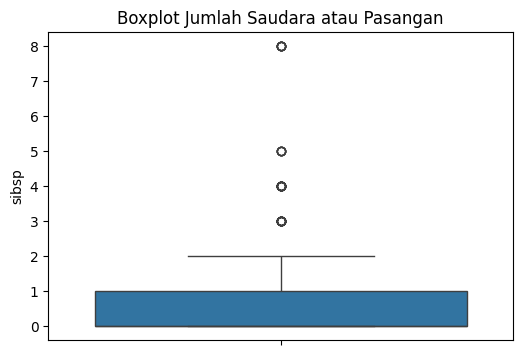

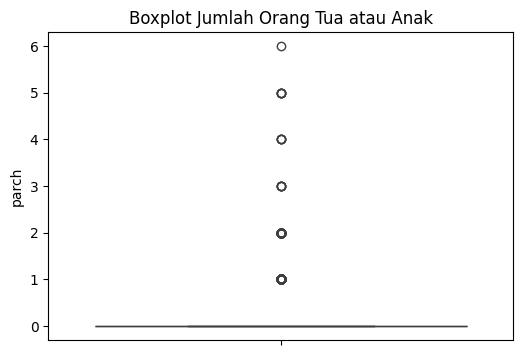

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.boxplot(y=df["sibsp"])
plt.title("Boxplot Jumlah Saudara atau Pasangan")
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(y=df["parch"])
plt.title("Boxplot Jumlah Orang Tua atau Anak")
plt.show()